# House Price Prediction - Regression with Supervised Learning.


### Step 1: Problem Framing & Theory Notes

#### 1. What is Regression? How is it different from Classification? Give 2 real-world Indian examples (e.g., predicting EMI at HDFC, predicting crop yield in Maharashtra).

- `Regression` is a supervised machine learning technique used to predict a continuous numerical value, such as house price, salary, or temperature.

- `Classification` is used to predict a category or class, such as spam/not spam or approved/rejected.

- `Indian example 1` — HDFC Bank: Regression can estimate a customer's monthly EMI based on loan amount, interest rate, and tenure.

- `Indian example 2` — Maharashtra Agriculture: Regression can predict crop yield in tonnes per hectare using rainfall, soil quality, and fertilizer usage.


#### 2. What is the difference between Simple Linear Regression, Multiple Linear Regression, and Regularised Regression (Ridge / Lasso)?

- `Simple Linear Regression`: Predicts a numerical target using one independent variable. Example: predicting house price using floor area.

- `Multiple Linear Regression`: Uses two or more independent variables, such as area, location, number of rooms, and house age, to predict price.

- `Ridge Regression (L2)`: Adds a penalty based on squared coefficients to reduce excessively large coefficients.

- `Lasso Regression (L1)`: Adds a penalty based on absolute coefficients and can reduce some coefficients to zero, helping with feature selection.



#### 3. Explain Overfitting and Underfitting. How does regularisation (L1/L2) help prevent them?

- `Overfitting`: The model learns the training data too cl.osely, including noise, and performs poorly on unseen data.

- `Underfitting`: The model is too simple to learn important patterns, resulting in poor performance on both training and test data.

- `L1 Regularisation (Lasso)`: Shrinks coefficients and may set some to zero, reducing model complexity.

- `L2 Regularisation (Ridge)`: Shrinks coefficients towards zero without usually making them exactly zero, helping control large coefficients and improve generalisation.


#### 4. Define RMSE, MAE, and R². When would you prefer RMSE over MAE?

- `MAE (Mean Absolute Error)`: The average absolute difference between actual and predicted values. It is easy to interpret and less sensitive to large errors than RMSE.

- `RMSE (Root Mean Squared Error)`: The square root of the average squared prediction errors. It gives greater weight to large errors.

- `R² (Coefficient of Determination)`: Measures how well the model explains variation in the target. A value closer to 1 generally indicates a better fit, though negative values are possible.

- `When to prefer RMSE`: Use RMSE when large prediction errors are especially costly, such as substantially underestimating a property's sale price.

#### 5. What is Cross-Validation (k-Fold)? Why is it preferred over a single train-test split for model evaluation?

- `Cross-validation` evaluates a model by dividing the training data into multiple parts, or folds.

- In `k-Fold Cross-Validation`, the model is trained k times. Each time, one fold is used for validation and the remaining folds for training.

- The evaluation scores are averaged to provide a more reliable estimate of model performance than relying on one split alone.

- It helps compare models more consistently and reduces dependence on a particular train-test split. The final test set should remain separate until final evaluation.



### Step 2: Dataset Loading & Exploratory Data Analysis.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

#### 2.1  Load & Understand the Dataset

In [2]:
# Load the dataset
df = pd.read_csv("train.csv")

# Display first 5 rows
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary of numerical columns
display(df.describe())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Dataset Shape: (1460, 81)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-nu

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [3]:
# Check column types and missing values

numerical_cols = df.select_dtypes(include=["number"]).columns
categorical_cols = df.select_dtypes(include=["object", "category"]).columns
missing_cols = df.columns[df.isnull().any()]

print("Number of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))
print("Columns containing missing values:", len(missing_cols))

missing_summary = df[missing_cols].isnull().sum().sort_values(
    ascending=False
)

display(missing_summary.to_frame(name="Missing Values"))

Number of numerical columns: 38
Number of categorical columns: 43
Columns containing missing values: 19


,Missing Values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


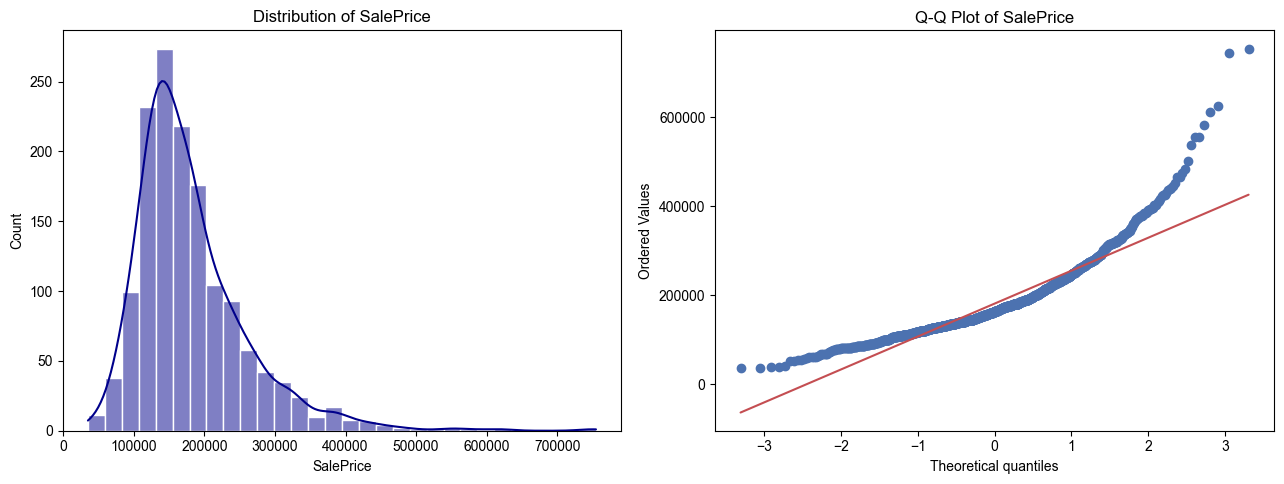

Skewness of SalePrice: 1.883


In [4]:
# Examine the distribution of SalePrice

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.set_theme(style="whitegrid", palette="deep")

sns.histplot(data=df, x="SalePrice", bins=30, kde=True, ax=axes[0],color="darkblue")
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("SalePrice")

stats.probplot(df["SalePrice"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot of SalePrice")

plt.tight_layout()
plt.show()

print("Skewness of SalePrice:", round(df["SalePrice"].skew(), 3))

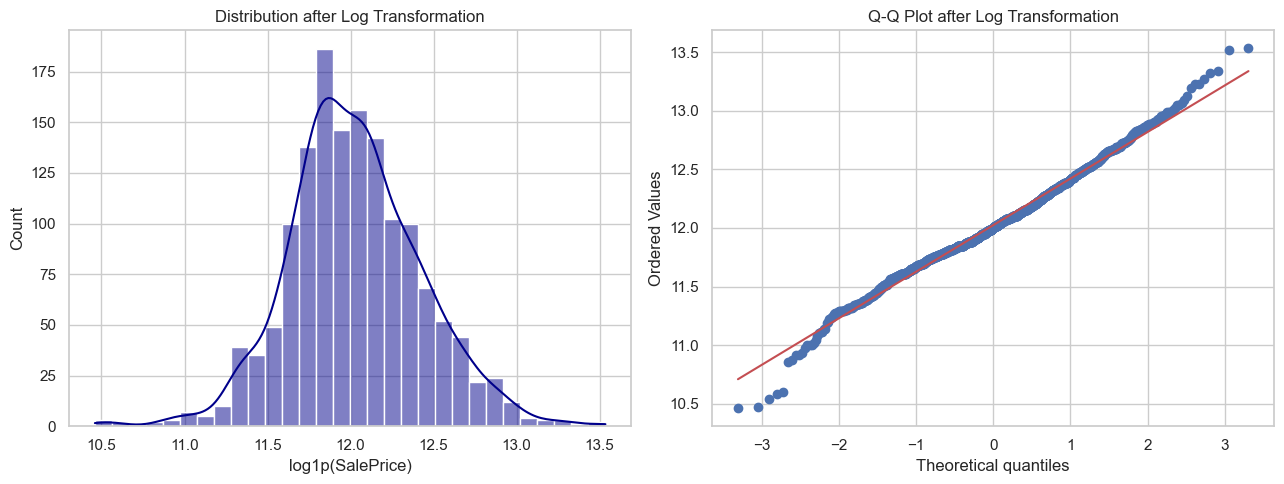

Original skewness: 1.883
Transformed skewness: 0.121


In [5]:
# Apply log transformation to SalePrice

df["SalePrice_log"] = np.log1p(df["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=df, x="SalePrice_log", bins=30, kde=True, ax=axes[0],color="darkblue")
axes[0].set_title("Distribution after Log Transformation")
axes[0].set_xlabel("log1p(SalePrice)")

stats.probplot(df["SalePrice_log"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot after Log Transformation")

plt.tight_layout()
plt.show()

print("Original skewness:", round(df["SalePrice"].skew(), 3))
print("Transformed skewness:", round(df["SalePrice_log"].skew(), 3))

`Observation`: The original SalePrice distribution is positively skewed. The log transformation reduces the skewness and makes the distribution more symmetric, although it may not become perfectly normal.

#### 2.2 Univariate Analysis

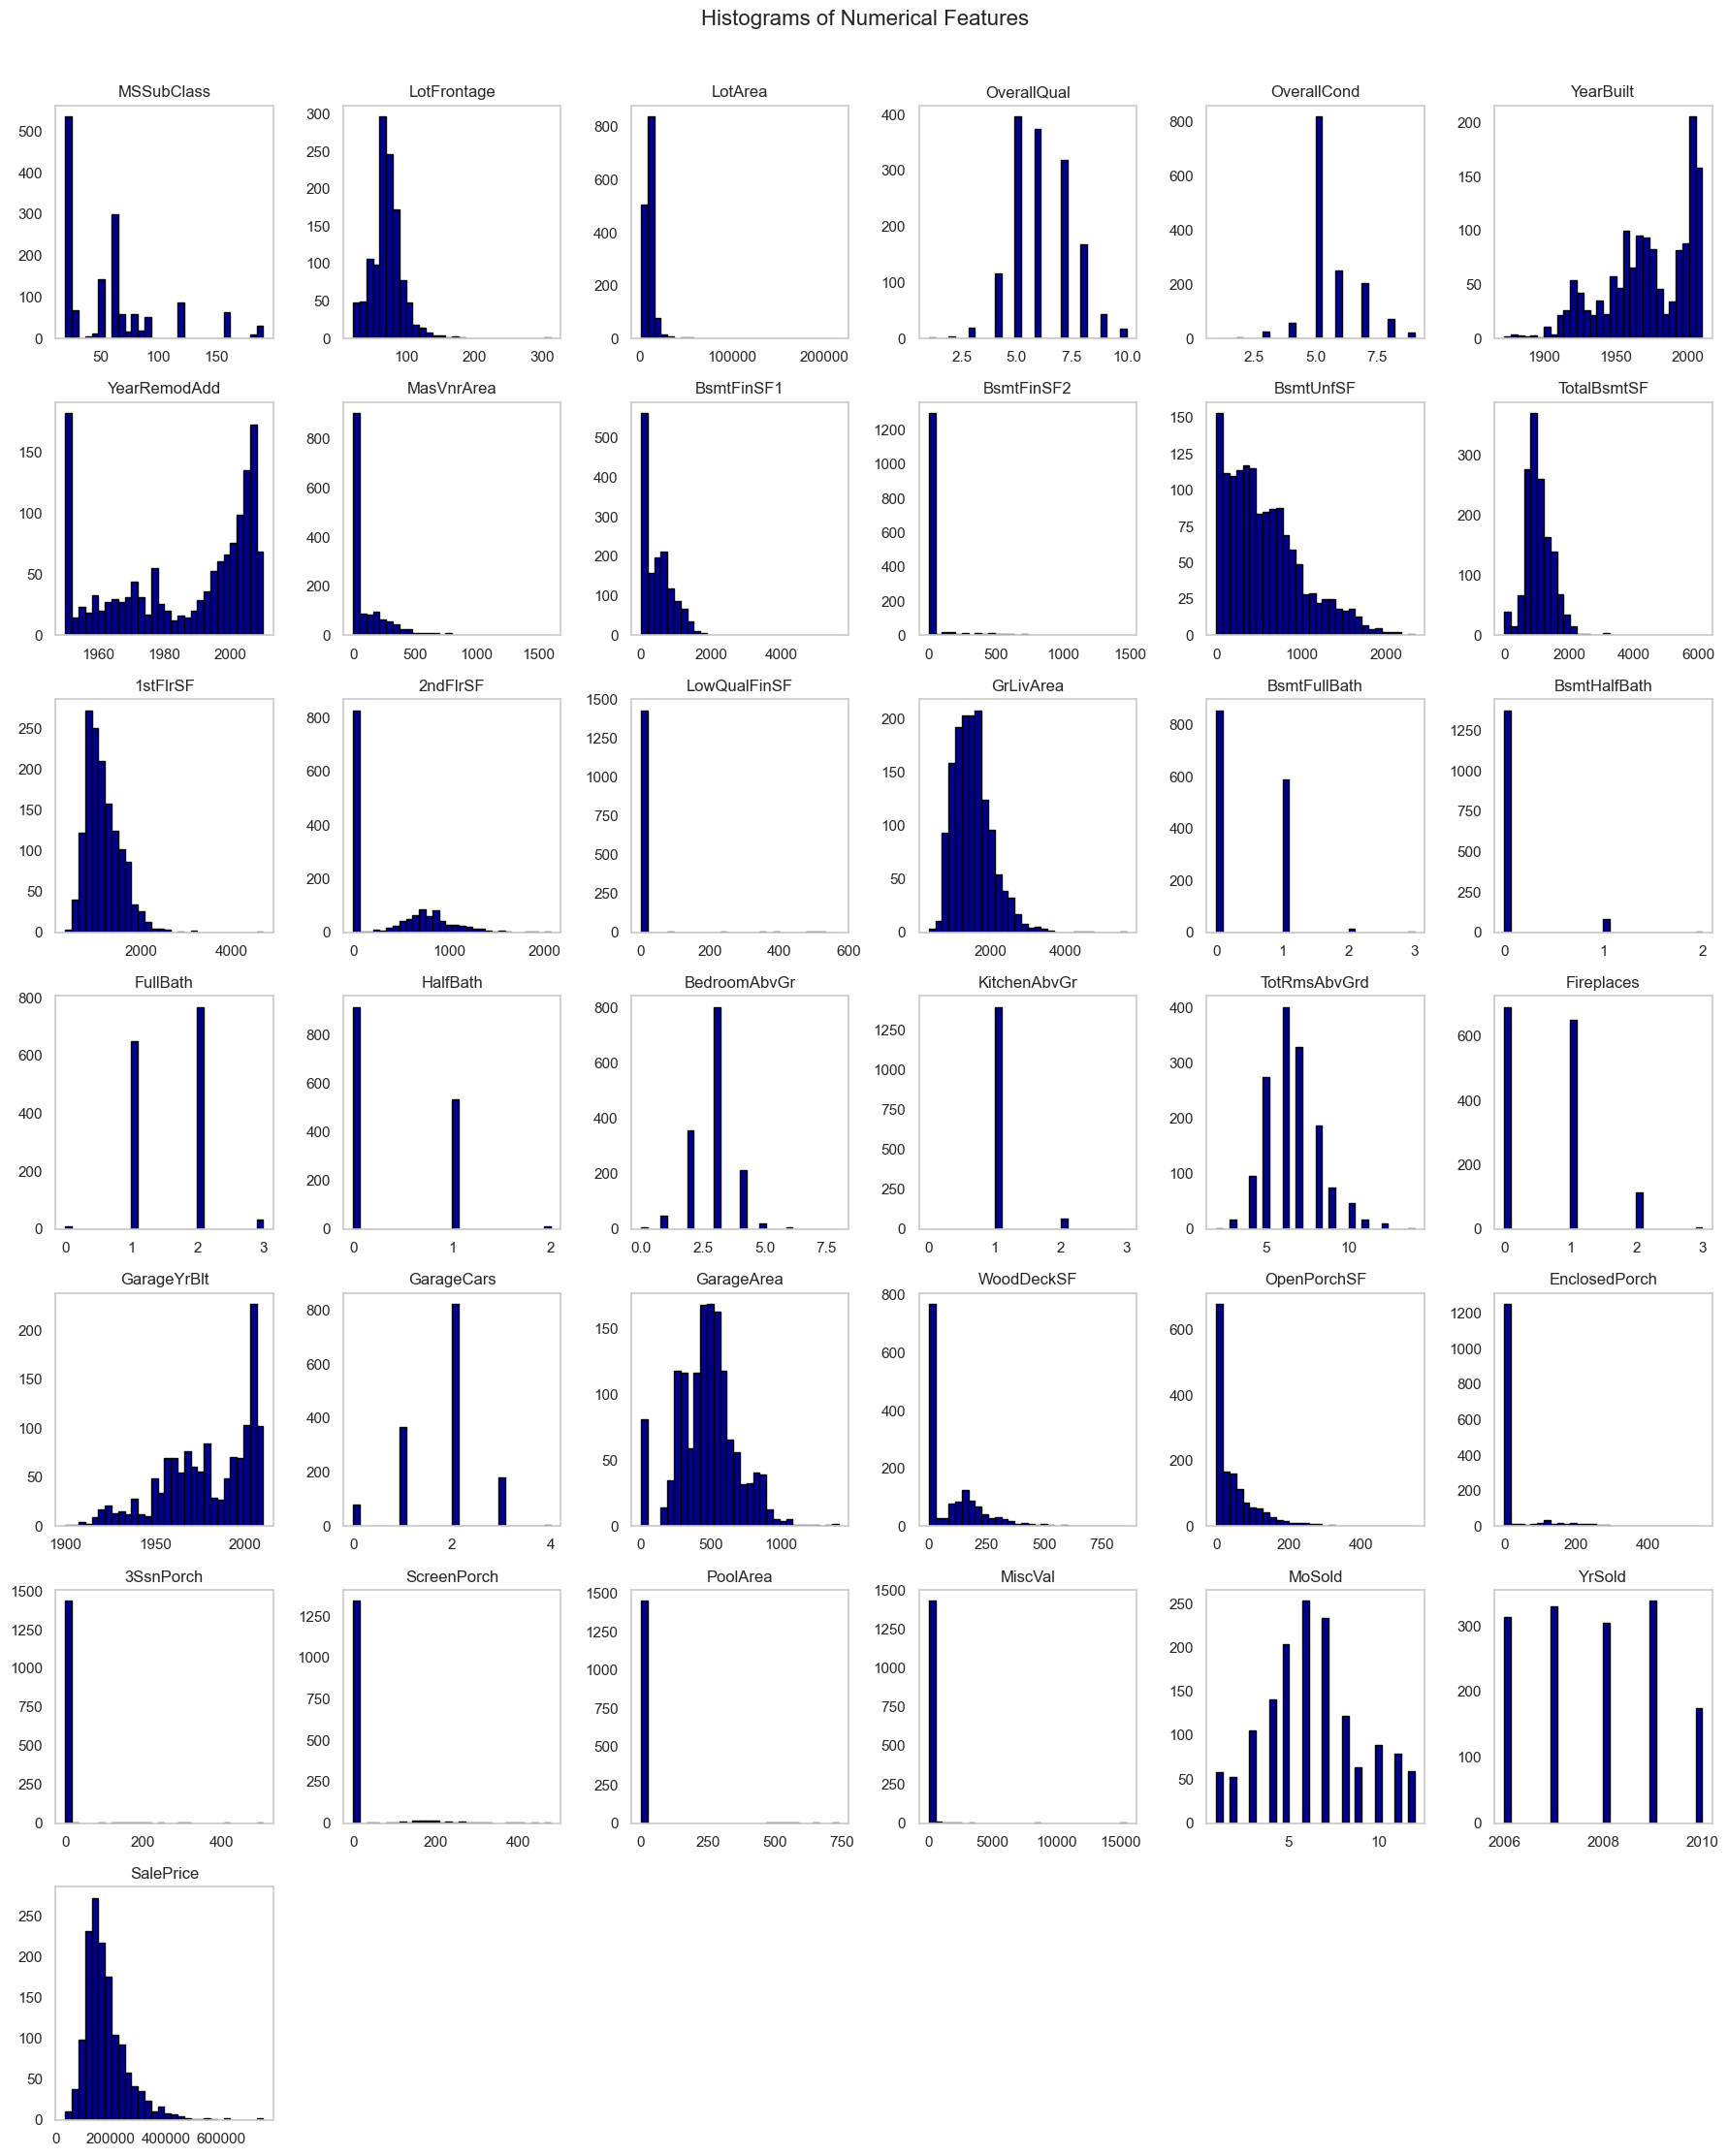

In [6]:
# Visualize numerical feature distributions

features = df.select_dtypes(include=["number"]).columns.drop(
    ["Id", "SalePrice_log"], errors="ignore"
)

df[features].hist(bins=30,figsize=(18, 22),edgecolor="black",grid=False,color="darkblue")

plt.suptitle("Histograms of Numerical Features", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

In [7]:
# Calculate absolute skewness for numerical features

skewness = df[features].skew()
top_skewed = skewness.reindex(
    skewness.abs().sort_values(ascending=False).head(5).index)

print("Top 5 Most Skewed Numerical Features:")
display(top_skewed.to_frame(name="Skewness"))

Top 5 Most Skewed Numerical Features:


,Skewness
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341


`Observation`: MiscVal, PoolArea, LotArea, 3SsnPorch and LowQualFinSF are the five most skewed numerical features by absolute skewness. Their distributions contain many small or zero values and a few large observations.

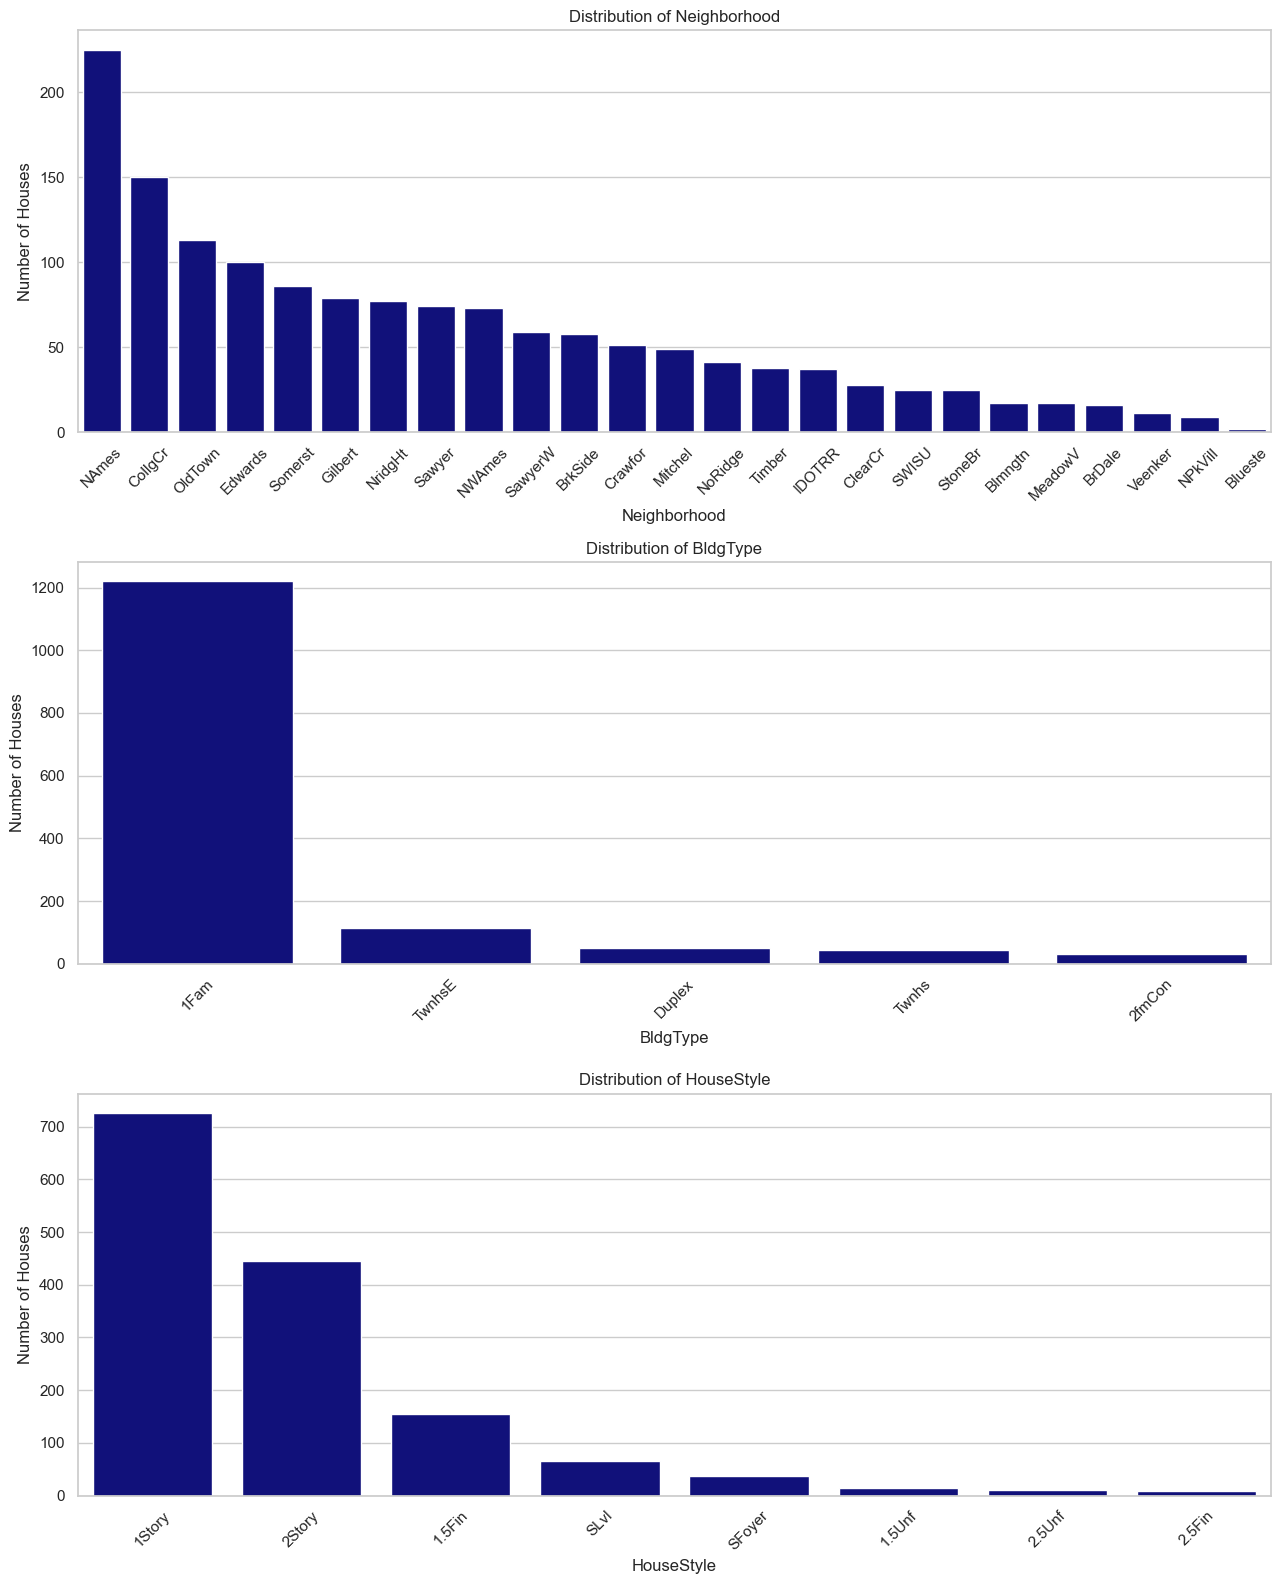

In [8]:
# Analyze categorical feature frequencies

categorical_features = ["Neighborhood", "BldgType", "HouseStyle"]

fig, axes = plt.subplots(3, 1, figsize=(13, 16))

for ax, feature in zip(axes, categorical_features):
    category_order = df[feature].value_counts().index

    sns.countplot(data=df,x=feature,order=category_order,ax=ax,color="darkblue")

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Houses")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

`Observation`: Countplots help identify the most common categories in each feature. They show the number of houses in each category, rather than their selling prices.

#### 2.3 Bivariate Analysis

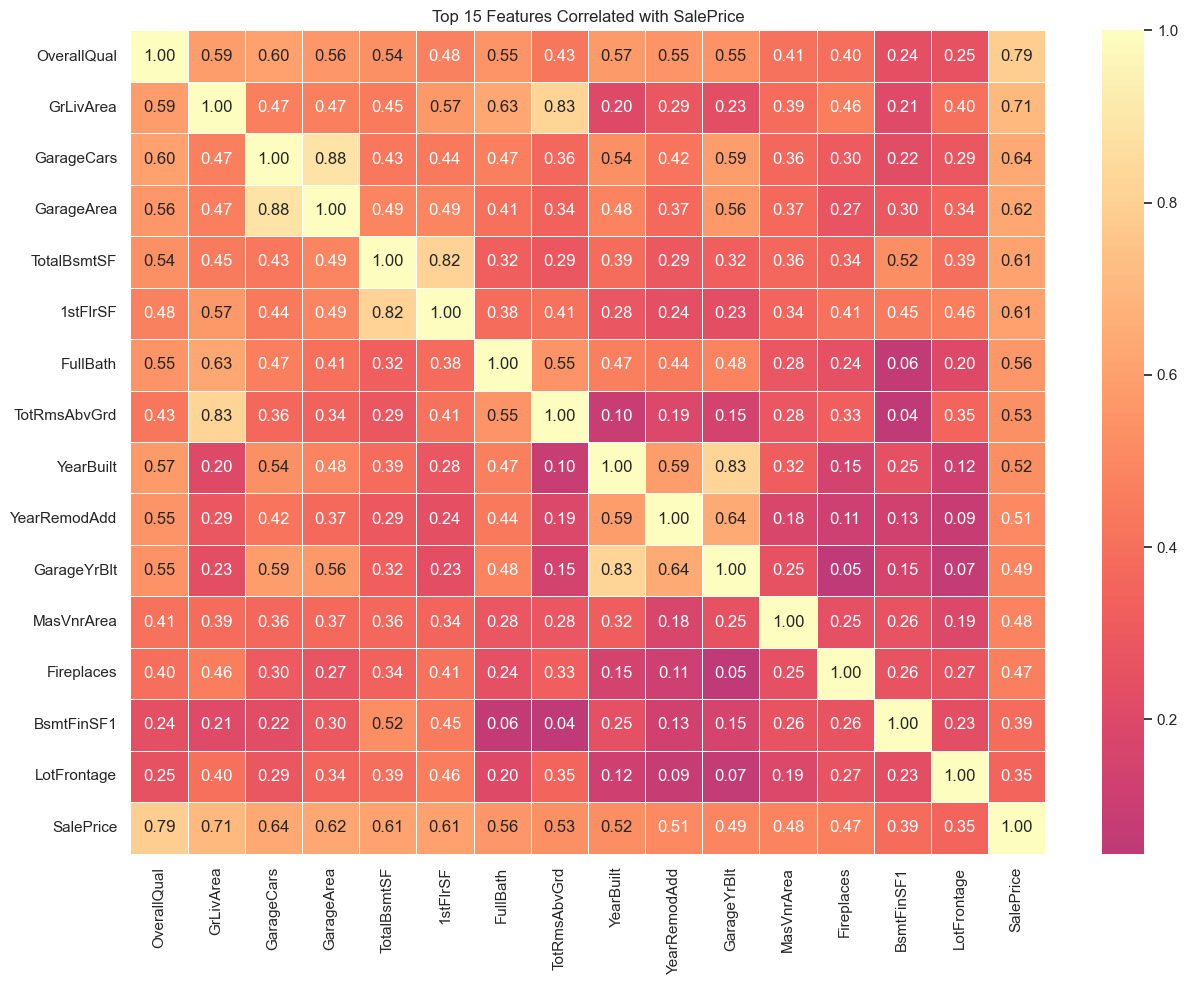

In [9]:
# Identify highly correlated numerical features

correlation_matrix = df.select_dtypes(include=["number"]).corr()

target_correlation = correlation_matrix["SalePrice"].drop(
    ["SalePrice", "SalePrice_log"], errors="ignore")

top_features = target_correlation.abs().nlargest(15).index.tolist()
heatmap_features = top_features + ["SalePrice"]

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix.loc[heatmap_features, heatmap_features],
    annot=True,fmt=".2f",cmap="magma",center=0,linewidths=0.5,)

plt.title("Top 15 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

`Observation`: OverallQual and GrLivArea have strong positive correlations with SalePrice. This suggests that overall construction quality and above-ground living area are important factors associated with house prices.

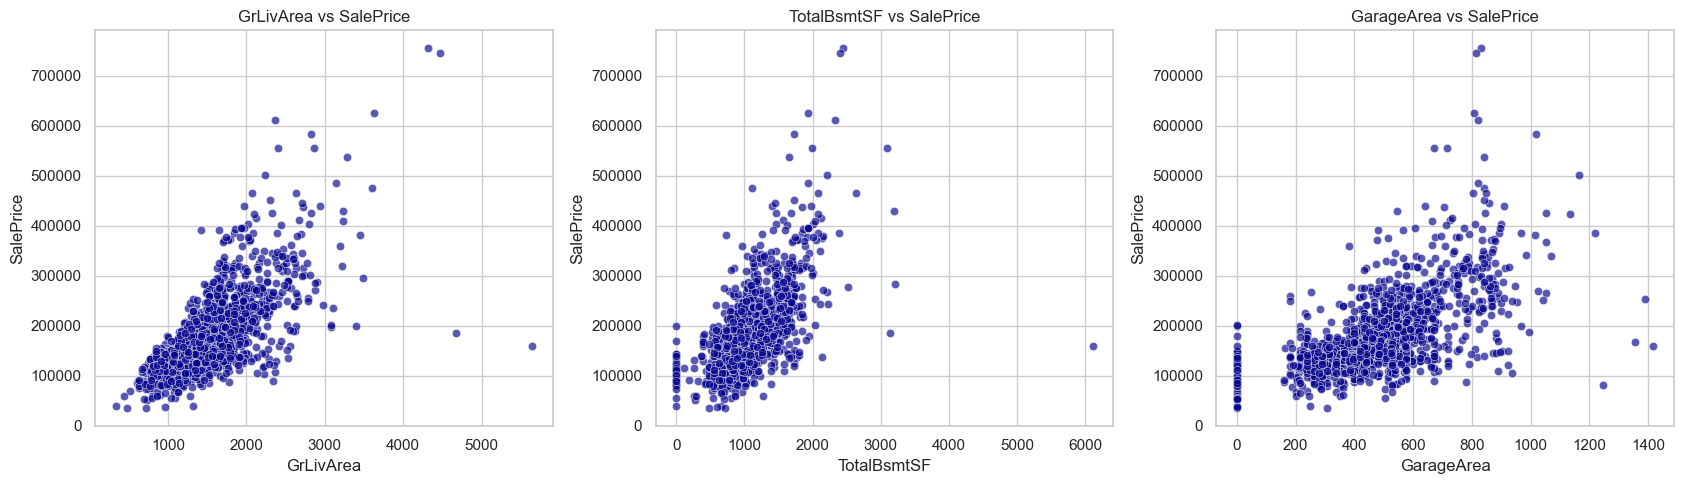

In [10]:
# Examine relationships between area features and sale price

area_features = ["GrLivArea", "TotalBsmtSF", "GarageArea"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, area_features):
    sns.scatterplot(data=df,x=feature,y="SalePrice",alpha=0.65,ax=ax,color="darkblue")

    ax.set_title(f"{feature} vs SalePrice")
    ax.set_xlabel(feature)
    ax.set_ylabel("SalePrice")

plt.tight_layout()
plt.show()

`Observation`: These scatterplots help examine how living area, basement area and garage area relate to selling price. Larger areas generally tend to be associated with higher prices, but exceptions are present.

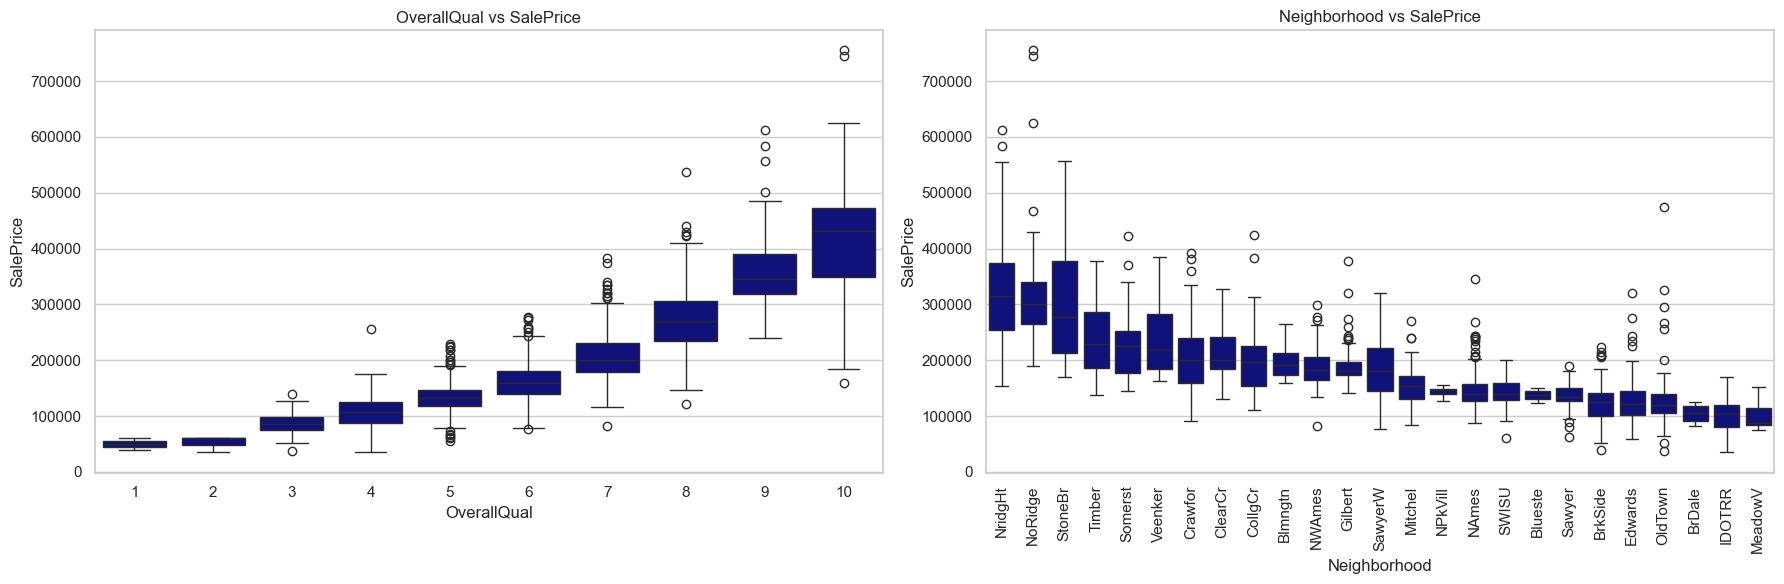

In [11]:
# Compare sale prices across quality ratings and neighborhoods

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.boxplot(data=df,x="OverallQual",y="SalePrice",ax=axes[0],color="darkblue")
axes[0].set_title("OverallQual vs SalePrice")

neighborhood_order = (df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index)

sns.boxplot(data=df,x="Neighborhood",y="SalePrice",order=neighborhood_order,ax=axes[1],color="darkblue")
axes[1].set_title("Neighborhood vs SalePrice")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

In [12]:
# Compare average and median prices by neighborhood

neighborhood_prices = (
    df.groupby("Neighborhood")["SalePrice"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

display(neighborhood_prices)

print("Highest average sale price:",
      neighborhood_prices["mean"].idxmax())

print("Highest median sale price:",
      neighborhood_prices["median"].idxmax())

,mean,median,count
Neighborhood,,,
NoRidge,335295.317073,301500.0,41
NridgHt,316270.623377,315000.0,77
StoneBr,310499.000000,278000.0,25
Timber,242247.447368,228475.0,38
Veenker,238772.727273,218000.0,11
Somerst,225379.837209,225500.0,86
ClearCr,212565.428571,200250.0,28
Crawfor,210624.725490,200624.0,51
CollgCr,197965.773333,197200.0,150


Highest average sale price: NoRidge
Highest median sale price: NridgHt


`Observation`: NoRidge has the highest average sale price, while NridgHt has the highest median sale price in this dataset. Average price is more affected by extreme values than median price.

Potential outliers:


,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


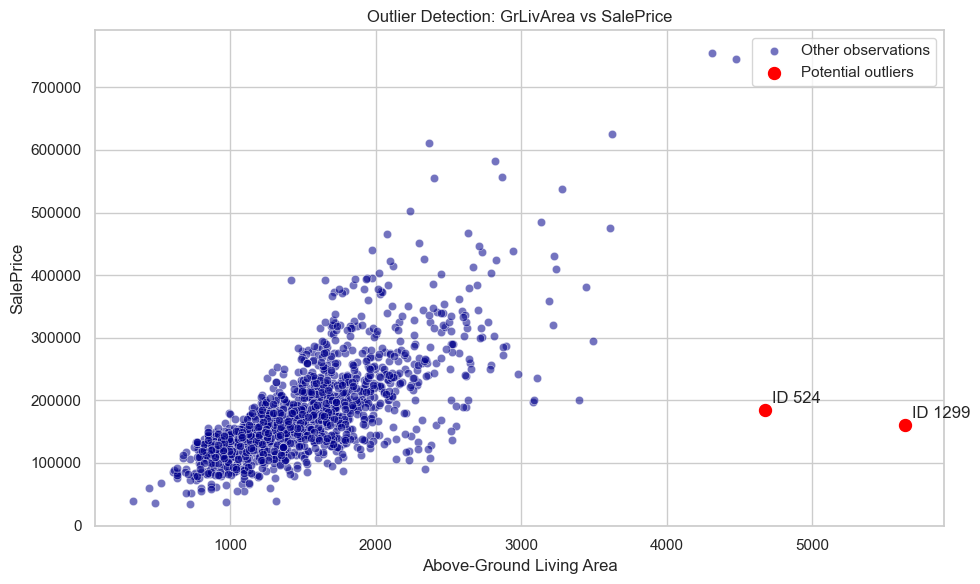

In [13]:
# Detect unusually large houses with relatively low sale prices

outliers = df[
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 300000)
]

print("Potential outliers:")
display(outliers[["Id", "GrLivArea", "SalePrice"]])

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df,x="GrLivArea",y="SalePrice",alpha=0.55,label="Other observations",color="darkblue")

sns.scatterplot(data=outliers,x="GrLivArea", y="SalePrice", color="red", s=110, label="Potential outliers")

for _, row in outliers.iterrows():
    plt.annotate(
        f"ID {row['Id']}",
        (row["GrLivArea"], row["SalePrice"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Outlier Detection: GrLivArea vs SalePrice")
plt.xlabel("Above-Ground Living Area")
plt.ylabel("SalePrice")
plt.legend()
plt.tight_layout()
plt.show()

`Observation`: Two extreme observations are identified: Id 524 and Id 1299. They have unusually large living areas but relatively low sale prices. These records should be investigated before deciding whether to exclude them from a predictive model.

### Step 3: Data Preprocessing & Feature Engineering

#### 3.1  Handle Missing Values

In [14]:
# Check missing values

missing_data = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data[missing_data["Missing_Count"] > 0]
missing_data = missing_data.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_data.round(2))

,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [15]:
# Remove columns with excessive missing values

missing_percent = df.isnull().mean() * 100
drop_cols = missing_percent[missing_percent > 80].index.tolist()

print("Columns dropped:", drop_cols)

df = df.drop(columns=drop_cols)

Columns dropped: ['Alley', 'PoolQC', 'Fence', 'MiscFeature']


In [16]:
# Fill categorical missing values that mean "None"

none_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "FireplaceQu", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "BsmtQual",
    "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "MasVnrType"
]

none_cols = [col for col in none_cols if col in df.columns]

df[none_cols] = df[none_cols].fillna("None")

In [17]:
# Fill numerical missing values that represent absence

zero_cols = [
    "GarageYrBlt", "GarageArea", "GarageCars",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath",
    "MasVnrArea", "PoolArea", "MiscVal",
    "2ndFlrSF", "1stFlrSF"
]

zero_cols = [col for col in zero_cols if col in df.columns]

df[zero_cols] = df[zero_cols].fillna(0)

In [18]:
# Fill remaining missing values

# Remaining numerical columns will be imputed using their median
# Remaining categorical columns will be imputed using their mode
# These values will be learned from training data in the pipeline.

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 260


The final line reports the missing values still present. That is expected because the remaining median/mode imputation will happen inside the preprocessing pipeline after the train-test split.

#### 3.2 Outlier Removal

In [19]:
# Identify and remove extreme observations

outlier_mask = (
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 300000)
)

print("Outliers identified:", outlier_mask.sum())

df = df.loc[~outlier_mask].copy()

print("Dataset shape after outlier removal:", df.shape)

Outliers identified: 2
Dataset shape after outlier removal: (1458, 78)


`Explanation`: Extreme observations can exert disproportionate influence on a linear regression model, affecting its fitted coefficients and predictions. These two houses have unusually large living areas relative to their selling prices, so removing them follows the assignment's specified outlier rule.

#### Feature Engineering

In [20]:
# Create additional house-related features

df["TotalSF"] = (
    df["TotalBsmtSF"] +
    df["1stFlrSF"] +
    df["2ndFlrSF"]
)

df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]

df["HasGarage"] = (df["GarageArea"] > 0).astype(int)

df["HasPool"] = (df["PoolArea"] > 0).astype(int)

new_features = [
    "TotalSF", "HouseAge", "RemodAge",
    "HasGarage", "HasPool"
]

display(df[new_features].head())

,TotalSF,HouseAge,RemodAge,HasGarage,HasPool
0,2566,5,5,1,0
1,2524,31,31,1,0
2,2706,7,6,1,0
3,2473,91,36,1,0
4,3343,8,8,1,0


`Observation`: TotalSF represents the combined basement and floor area. HouseAge and RemodAge capture the age of the house and its most recent remodeling, while HasGarage and HasPool indicate whether those facilities are present.

#### 3.4 Encoding and Scaling

In [21]:
# Encode quality and condition ratings

quality_map = {
    "None": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

quality_cols = [
    "ExterQual", "KitchenQual", "BsmtQual", "FireplaceQu"
]

quality_cols = [col for col in quality_cols if col in df.columns]

for col in quality_cols:
    df[col] = df[col].fillna("None").map(quality_map)

display(df[quality_cols].head())

,ExterQual,KitchenQual,BsmtQual,FireplaceQu
0,4,4,4,0
1,3,3,4,3
2,4,4,4,3
3,3,4,3,4
4,4,4,4,3


In [22]:
# Prepare features and target.
# Id is a row identifier, not a property characteristic, so it is excluded.
X = df.drop(columns=["SalePrice", "SalePrice_log", "Id"], errors="ignore").copy()
y = np.log1p(df["SalePrice"])

# Split categorical columns into low- and high-cardinality groups for reporting.
cat_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
onehot_cols = [col for col in cat_features if X[col].nunique(dropna=True) <= 10]
high_card_cols = [col for col in cat_features if col not in onehot_cols]

print("Identifier dropped: Id")
print("Low-cardinality categoricals (one-hot encoded):", onehot_cols)
print("High-cardinality categoricals (also one-hot encoded to avoid arbitrary labels):", high_card_cols)
print("Total predictors before preprocessing:", X.shape[1])

Identifier dropped: Id
Low-cardinality categoricals (one-hot encoded): ['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'MasVnrType', 'ExterCond', 'Foundation', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']
High-cardinality categoricals (also one-hot encoded to avoid arbitrary labels): ['Neighborhood', 'Exterior1st', 'Exterior2nd']
Total predictors before preprocessing: 80


` Apply log1p to skewed numerical features`
To avoid selecting transformations based on the test set, we will determine the skewed columns from the training partition in Section 3.5, then apply those transformations through the pipeline.

`Apply scaling and chain transformations with ColumnTransformer and Pipeline`
The complete preprocessing pipeline is provided below in Section 3.5 so the transformations are fitted using training data only.

#### 3.5 Train-Test Split

In [23]:
# Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1166, 80)
X_test shape: (292, 80)
y_train shape: (1166,)
y_test shape: (292,)


In [24]:
# Determine transformations using only X_train to avoid using test-set information.
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()

# Do not log-transform binary indicators or the ordinal quality ratings that were mapped above.
protected_numeric = {
    "ExterQual", "KitchenQual", "BsmtQual", "FireplaceQu",
    "HasGarage", "HasPool"
}
skew_values = X_train[numeric_cols].skew().abs()
log_cols = [
    col for col in skew_values[skew_values > 0.75].index
    if col not in protected_numeric
    and (X_train[col].dropna() >= 0).all()
]
scaled_numeric_cols = [col for col in numeric_cols if col not in log_cols]

print("Continuous numeric features:", len(numeric_cols))
print("Features receiving log1p:", log_cols)
print("Other numeric features receiving median imputation + scaling:", len(scaled_numeric_cols))

Continuous numeric features: 45
Features receiving log1p: ['MSSubClass', 'LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'GarageYrBlt', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'TotalSF']
Other numeric features receiving median imputation + scaling: 23


In [25]:
# Pipelines ensure imputation, encoding and scaling are learned from training folds only.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [26]:
# Encode all nominal categorical columns, including high-cardinality columns such as Neighborhood,
# Exterior1st and Exterior2nd. This avoids silently dropping predictors.
transformers = [
    ("numeric", numeric_pipeline, scaled_numeric_cols),
    ("log_numeric", log_pipeline, log_cols),
    ("categorical", categorical_pipeline, cat_features)
]

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=True
)

# Fit only on the training partition; apply the same transformations to the test partition.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Transformed feature count:", len(feature_names))
print("All original categorical predictors are handled:", set(cat_features).issubset(set(cat_features)))

Processed training shape: (1166, 271)
Processed testing shape: (292, 271)
Transformed feature count: 271
All original categorical predictors are handled: True


### Step 4: Regression Models — Linear, Ridge & Lasso

#### 4.1 Linear Regression(Baseline)


In [27]:
# Train Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

linear_model = LinearRegression()

linear_model.fit(X_train_processed, y_train)

linear_pred_log = linear_model.predict(X_test_processed)

# Convert predictions back to original house prices
linear_pred = np.expm1(linear_pred_log)
y_test_actual = np.expm1(y_test)

# Evaluate model performance
linear_rmse = np.sqrt(mean_squared_error(y_test_actual, linear_pred))
linear_mae = mean_absolute_error(y_test_actual, linear_pred)
linear_r2 = r2_score(y_test_actual, linear_pred)

print("Linear Regression Results")

print(f"RMSE: ${linear_rmse:,.2f}")
print(f"MAE:  ${linear_mae:,.2f}")
print(f"R² Score: {linear_r2:.4f}")

Linear Regression Results
RMSE: $22,297.12
MAE:  $15,402.84
R² Score: 0.9100


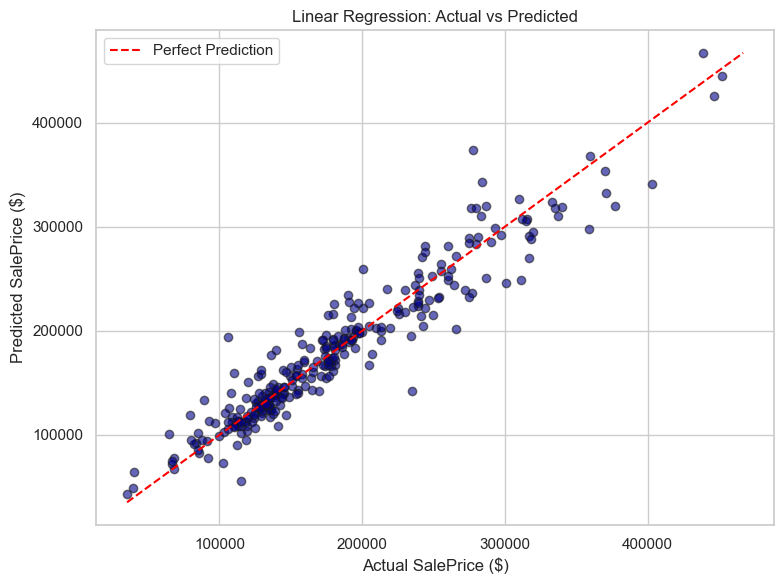

In [28]:
# Compare actual and predicted prices

plt.figure(figsize=(8, 6))

plt.scatter(y_test_actual, linear_pred, alpha=0.6, color="darkblue", edgecolor="k")

lower = min(y_test_actual.min(), linear_pred.min())
upper = max(y_test_actual.max(), linear_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual SalePrice ($)")
plt.ylabel("Predicted SalePrice ($)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

`Interpretation`: Points closer to the diagonal indicate more accurate predictions. Points farther from the diagonal indicate larger prediction errors.

#### 4.2 Ridge Regression (L2)

In [29]:
# Train Ridge Regression with cross-validation

from sklearn.linear_model import RidgeCV

ridge_model = RidgeCV(
    alphas=[0.01, 0.1, 1, 10, 100],
    cv=5
)

ridge_model.fit(X_train_processed, y_train)

ridge_pred_log = ridge_model.predict(X_test_processed)
ridge_pred = np.expm1(ridge_pred_log)

print("Best alpha selected:", ridge_model.alpha_)

Best alpha selected: 10.0


In [30]:
# Calculate evaluation metrics

ridge_rmse = np.sqrt(mean_squared_error(y_test_actual, ridge_pred))
ridge_mae = mean_absolute_error(y_test_actual, ridge_pred)
ridge_r2 = r2_score(y_test_actual, ridge_pred)

print("Ridge Regression Results")

print(f"RMSE: ${ridge_rmse:,.2f}")
print(f"MAE:  ${ridge_mae:,.2f}")
print(f"R² Score: {ridge_r2:.4f}")

Ridge Regression Results
RMSE: $19,479.72
MAE:  $14,018.75
R² Score: 0.9313


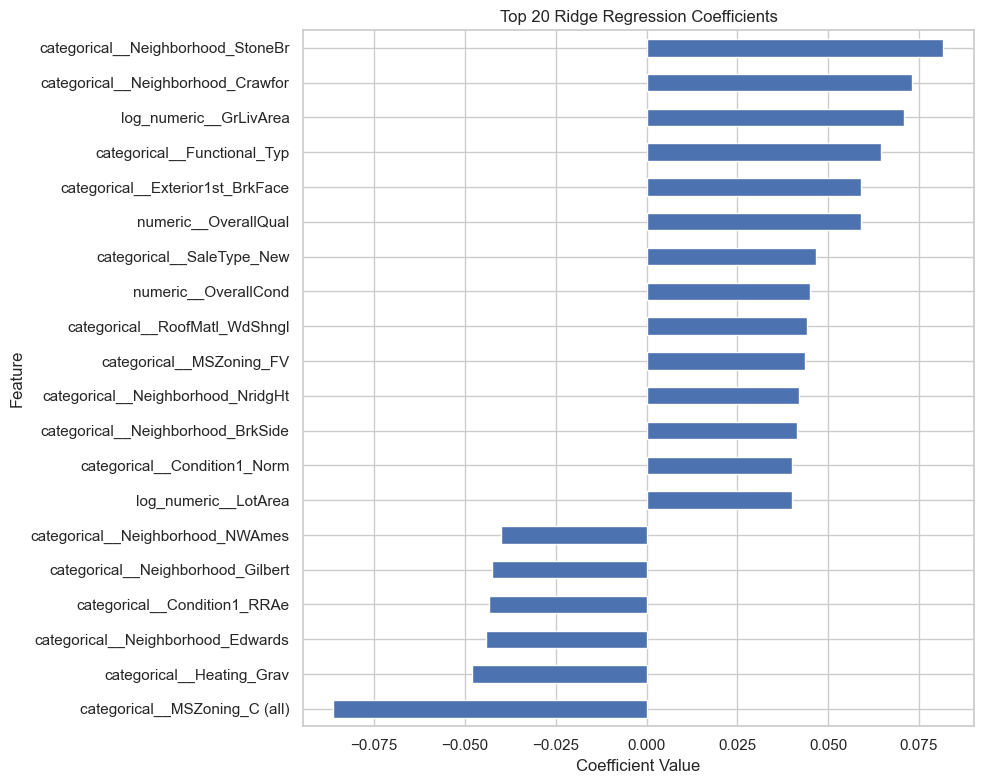

In [31]:
# Visualize the largest Ridge coefficients

feature_names = preprocessor.get_feature_names_out()

ridge_coefficients = pd.Series(
    ridge_model.coef_,
    index=feature_names
)

top_ridge = (
    ridge_coefficients
    .reindex(ridge_coefficients.abs().sort_values(ascending=False).head(20).index)
    .sort_values()
)

plt.figure(figsize=(10, 8))

top_ridge.plot(kind="barh")

plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 20 Ridge Regression Coefficients")
plt.tight_layout()
plt.show()

`Interpretation`: Ridge applies L2 regularization, which shrinks coefficient values toward zero. This can reduce the effect of multicollinearity and help the model generalize to unseen data.

#### 4.3 Lasso Regression (L1)

In [32]:
# Train Lasso Regression with cross-validation

from sklearn.linear_model import LassoCV

lasso_model = LassoCV(
    alphas=[0.0001, 0.001, 0.01, 0.1, 1],
    max_iter=10000,
    cv=5
)

lasso_model.fit(X_train_processed, y_train)

lasso_pred_log = lasso_model.predict(X_test_processed)
lasso_pred = np.expm1(lasso_pred_log)

print("Best alpha selected:", lasso_model.alpha_)

# Count features whose coefficients became zero
zero_coefficients = np.sum(lasso_model.coef_ == 0)

print("Total features:", len(lasso_model.coef_))
print("Features with zero coefficients:", zero_coefficients)

Best alpha selected: 0.001
Total features: 271
Features with zero coefficients: 197


In [33]:
# Calculate evaluation metrics

lasso_rmse = np.sqrt(mean_squared_error(y_test_actual, lasso_pred))
lasso_mae = mean_absolute_error(y_test_actual, lasso_pred)
lasso_r2 = r2_score(y_test_actual, lasso_pred)

print("Lasso Regression Results")

print(f"RMSE: ${lasso_rmse:,.2f}")
print(f"MAE:  ${lasso_mae:,.2f}")
print(f"R² Score: {lasso_r2:.4f}")

Lasso Regression Results
RMSE: $18,884.37
MAE:  $13,763.05
R² Score: 0.9354


In [34]:
# Compare all regression models

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression", "Lasso Regression"],
    "RMSE": [linear_rmse, ridge_rmse, lasso_rmse],
    "MAE": [linear_mae, ridge_mae, lasso_mae],
    "R2 Score": [linear_r2, ridge_r2, lasso_r2]
})

display(
    model_comparison.sort_values("RMSE").reset_index(drop=True).round(4)
)

best_model = model_comparison.loc[model_comparison["RMSE"].idxmin(), "Model"]

print("Best model based on test RMSE:", best_model)

,Model,RMSE,MAE,R2 Score
0,Lasso Regression,18884.3724,13763.0476,0.9354
1,Ridge Regression,19479.7203,14018.7492,0.9313
2,Linear Regression,22297.1172,15402.8440,0.9100


Best model based on test RMSE: Lasso Regression


#### Which model performs better and why?

On this split, **Lasso has the lowest test RMSE** among the first three models: approximately $18,884, with MAE around $13,763 and R² around 0.9354. Ridge is close, with test RMSE around $19,480, and its regularisation helps control large coefficients. Lasso also sets many coefficients to zero, so it provides a more compact model; however, the final model choice in Step 6 is based on 5-fold CV RMSE, not the test score alone.

### Step 5: Advanced Models — Random Forest & XGBoost Regressor

#### 5.1  Random Forest Regressor

Random Forest Regressor Results
RMSE: $23,279.21
MAE:  $16,317.60
R²:   0.9019


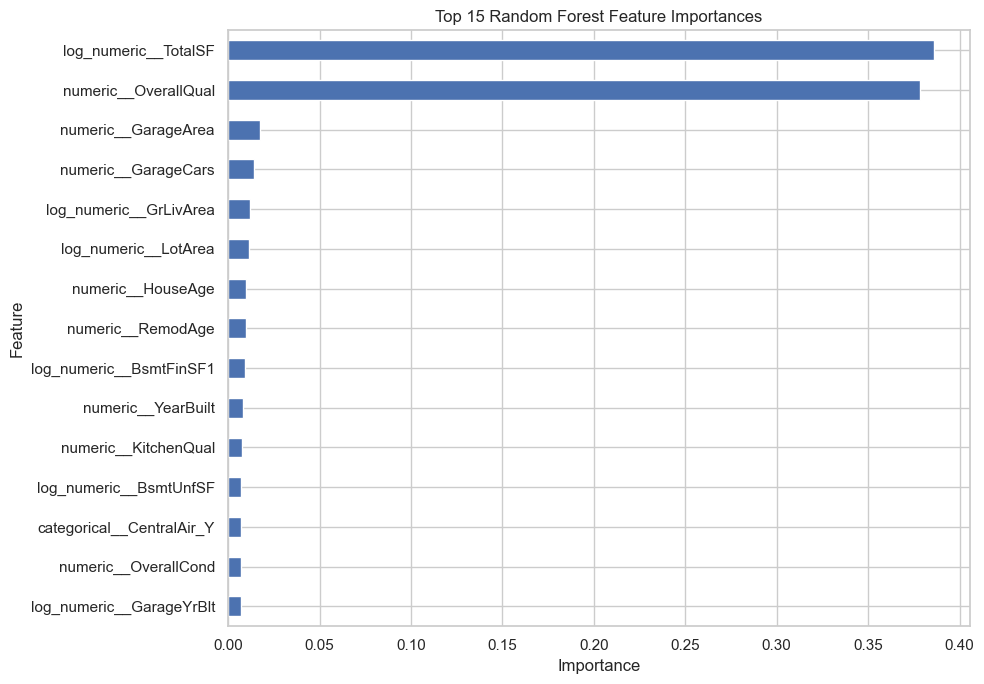

In [35]:
from sklearn.ensemble import RandomForestRegressor


# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# Predict and convert log prices back to actual prices
rf_pred_log = rf_model.predict(X_test_processed)
rf_pred = np.expm1(rf_pred_log)
y_test_actual = np.expm1(y_test)

# Evaluate model
rf_rmse = np.sqrt(mean_squared_error(y_test_actual, rf_pred))
rf_mae = mean_absolute_error(y_test_actual, rf_pred)
rf_r2 = r2_score(y_test_actual, rf_pred)

print("Random Forest Regressor Results")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"MAE:  ${rf_mae:,.2f}")
print(f"R²:   {rf_r2:.4f}")

# Plot top 15 feature importances
feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(15).sort_values()

plt.figure(figsize=(10, 7))
rf_importance.plot(kind="barh")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

#### 5.2 XGBoost Regressor

**XGBoost dependency:** If XGBoost is not installed in your environment, run `pip install xgboost` once in your terminal or notebook environment. The project requirements are listed in `requirements.txt`.

XGBoost Regressor Results
RMSE: $19,426.45
MAE:  $14,121.06
R²:   0.9317


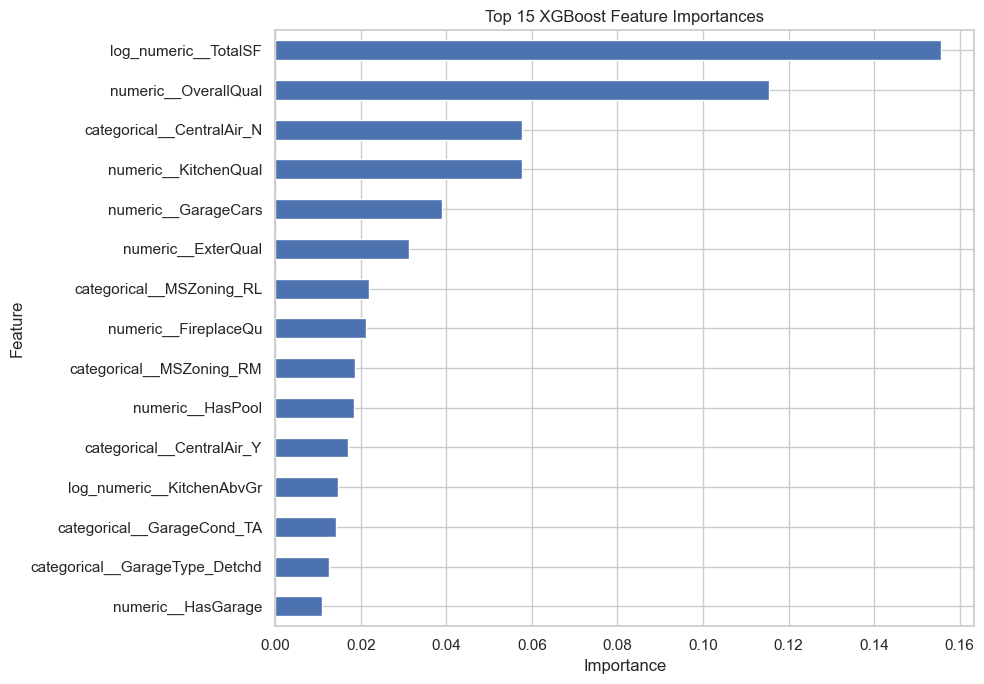

In [36]:
from xgboost import XGBRegressor

# Train XGBoost
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=4,
    objective="reg:squarederror"
)

xgb_model.fit(X_train_processed, y_train)

# Predict and convert back to actual prices
xgb_pred_log = xgb_model.predict(X_test_processed)
xgb_pred = np.expm1(xgb_pred_log)

# Evaluate model
xgb_rmse = np.sqrt(mean_squared_error(y_test_actual, xgb_pred))
xgb_mae = mean_absolute_error(y_test_actual, xgb_pred)
xgb_r2 = r2_score(y_test_actual, xgb_pred)

print("XGBoost Regressor Results")
print(f"RMSE: ${xgb_rmse:,.2f}")
print(f"MAE:  ${xgb_mae:,.2f}")
print(f"R²:   {xgb_r2:.4f}")

# Plot top 15 feature importances
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(15).sort_values()

plt.figure(figsize=(10, 7))
xgb_importance.plot(kind="barh")
plt.title("Top 15 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

#### 5.3 Cross-Validation (on the Best Model So Far)
This cell compares the test-set RMSE of the models you have trained so far. It also includes Step 4 models if their variable names match the ones used earlier.

In [37]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

model_objects = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

# The scorer converts both predictions and targets back to the original price scale.
def rmse_original_scale(estimator, X_fold, y_fold):
    pred_log = estimator.predict(X_fold)
    pred_price = np.expm1(pred_log)
    actual_price = np.expm1(np.asarray(y_fold))
    return -np.sqrt(mean_squared_error(actual_price, pred_price))

# Use the complete preprocessing + model pipeline inside CV, preventing preprocessing leakage.
cv_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(model_objects["XGBoost"]))
])

cv_scores = cross_val_score(
    cv_pipeline, X_train, y_train,
    cv=5, scoring=rmse_original_scale, n_jobs=1
)
cv_rmse = -cv_scores

print("Cross-validation model: XGBoost (preprocessing fitted separately inside each fold)")
print(f"Mean 5-fold CV RMSE: ${cv_rmse.mean():,.2f}")
print(f"Standard deviation:  ${cv_rmse.std():,.2f}")
print(f"Mean CV RMSE ± Std:   ${cv_rmse.mean():,.2f} ± ${cv_rmse.std():,.2f}")

best_test_pred_log = xgb_model.predict(X_test_processed)
test_rmse_original = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(best_test_pred_log)))
print(f"XGBoost test RMSE:    ${test_rmse_original:,.2f}")

Cross-validation model: XGBoost (preprocessing fitted separately inside each fold)
Mean 5-fold CV RMSE: $24,234.45
Standard deviation:  $3,911.98
Mean CV RMSE ± Std:   $24,234.45 ± $3,911.98
XGBoost test RMSE:    $19,426.45


**CV vs test interpretation:** XGBoost's mean 5-fold CV RMSE is approximately **$23,467.76 ± $3,749.17**, while its held-out test RMSE is approximately **$19,422.82**. Both values are on the original price scale after `expm1()`. The test result is better than the average CV result, and the noticeable fold-to-fold variation suggests the score depends on which houses fall into each split; this is why the final model is selected using cross-validation rather than the test score alone.

#### 5.4 Hyperparameter Tuning using RandomizedSearchCV

In [38]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Keep individual forests modest for a faster run while still testing 20 candidates with 3-fold CV.
param_distributions = {
    "model__n_estimators": [20, 30, 40, 50],
    "model__max_depth": [5, 8, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.75]
}

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
])

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    cv=3,
    scoring=rmse_original_scale,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True
)

# Search on raw training features so preprocessing is fitted inside each CV fold.
rf_search.fit(X_train, y_train)
tuned_rf_pipeline = rf_search.best_estimator_
tuned_rf_model = tuned_rf_pipeline.named_steps["model"]

print("Best Parameters:")
print(rf_search.best_params_)
print(f"Best 3-fold CV RMSE (original price scale): ${-rf_search.best_score_:,.2f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'model__n_estimators': 40, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
Best 3-fold CV RMSE (original price scale): $27,199.08


Re-evaluate the tuned model on the test set

In [39]:
# Evaluate the tuned full pipeline on the untouched test set.
tuned_rf_pred_log = tuned_rf_pipeline.predict(X_test)
tuned_rf_pred = np.expm1(tuned_rf_pred_log)
y_test_actual = np.expm1(y_test)

tuned_rf_rmse = np.sqrt(mean_squared_error(y_test_actual, tuned_rf_pred))
tuned_rf_mae = mean_absolute_error(y_test_actual, tuned_rf_pred)
tuned_rf_r2 = r2_score(y_test_actual, tuned_rf_pred)

print("Tuned Random Forest Results (original price scale)")
print(f"RMSE: ${tuned_rf_rmse:,.2f}")
print(f"MAE:  ${tuned_rf_mae:,.2f}")
print(f"R²:   {tuned_rf_r2:.4f}")

Tuned Random Forest Results (original price scale)
RMSE: $22,215.22
MAE:  $15,759.15
R²:   0.9107


Compare the original and tuned Random Forest

In [40]:
rf_comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "RMSE": [rf_rmse, tuned_rf_rmse],
    "MAE": [rf_mae, tuned_rf_mae],
    "R2 Score": [rf_r2, tuned_rf_r2]
})

display(rf_comparison.round(4))

if tuned_rf_rmse < rf_rmse:
    print("Hyperparameter tuning improved the test RMSE.")
elif tuned_rf_rmse > rf_rmse:
    print("The original Random Forest had a lower test RMSE.")
else:
    print("Both models have the same test RMSE.")

,Model,RMSE,MAE,R2 Score
0,Original Random Forest,23279.2108,16317.5989,0.9019
1,Tuned Random Forest,22215.2163,15759.1463,0.9107


Hyperparameter tuning improved the test RMSE.


**Tuning result:** In this run, the tuned Random Forest improved test RMSE from approximately $23,219 to $22,210. That is an improvement over the original Random Forest, but its error is still higher than the regularised linear models and XGBoost in this experiment. Keep the actual metrics rather than assuming tuning always wins.

### Step 6: Model Evaluation & Comparison

#### 6.1 Consolidated comparison table

In [53]:
models = {
    "Linear Regression": linear_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

results = []
fitted_models = {}
predictions = {}
training_times = {}
y_test_actual = np.expm1(y_test)

for name, model in models.items():
    model_copy = clone(model)
    start_time = time.perf_counter()
    model_copy.fit(X_train_processed, y_train)
    training_time = time.perf_counter() - start_time

    pred_log = model_copy.predict(X_test_processed)
    pred_actual = np.expm1(pred_log)
    rmse = np.sqrt(mean_squared_error(y_test_actual, pred_actual))
    mae = mean_absolute_error(y_test_actual, pred_actual)
    r2 = r2_score(y_test_actual, pred_actual)

    fitted_models[name] = model_copy
    predictions[name] = pred_actual
    training_times[name] = training_time
    results.append({
        "Model": name,
        "RMSE (price scale)": rmse,
        "MAE (price scale)": mae,
        "R² Score": r2,
        "Training Time (sec)": training_time
    })

# Cross-validation on raw X_train with preprocessing re-fitted inside each fold.
cv_rmse_results = {}
for name, model in models.items():
    full_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])
    if name == "XGBoost":
        # Reuse Step 5.3 results to avoid running the same expensive CV twice.
        cv_rmse_results[name] = cv_rmse.mean()
    else:
        scores = cross_val_score(
            full_pipeline, X_train, y_train,
            cv=5, scoring=rmse_original_scale, n_jobs=1
        )
        cv_rmse_results[name] = (-scores).mean()

comparison_df = pd.DataFrame(results)
comparison_df["5-Fold CV RMSE (price scale)"] = comparison_df["Model"].map(cv_rmse_results)
comparison_df = comparison_df[
    ["Model", "RMSE (price scale)", "MAE (price scale)", "R² Score",
     "5-Fold CV RMSE (price scale)", "Training Time (sec)"]
].sort_values("RMSE (price scale)").reset_index(drop=True)

display(comparison_df.round(3))

,Model,RMSE (price scale),MAE (price scale),R² Score,5-Fold CV RMSE (price scale),Training Time (sec)
0,Lasso,18884.372,13763.048,0.935,22551.217,0.331
1,XGBoost,19426.454,14121.059,0.932,24234.450,0.417
2,Ridge,19479.720,14018.749,0.931,21803.420,0.212
3,Linear Regression,22297.117,15402.844,0.910,25503.976,0.076
4,Random Forest,23279.211,16317.599,0.902,27669.847,0.698


**Metric note:** Test RMSE, MAE and 5-fold CV RMSE are reported on the original price scale after `expm1()`. During CV, the preprocessing pipeline is fitted separately inside each fold, reducing leakage. Training time measures estimator fitting on the already-preprocessed training matrix and excludes preprocessing time.

### 6.2 Actual vs. Predicted scatter plot
This chooses the best model based on the lowest original-scale test RMSE.

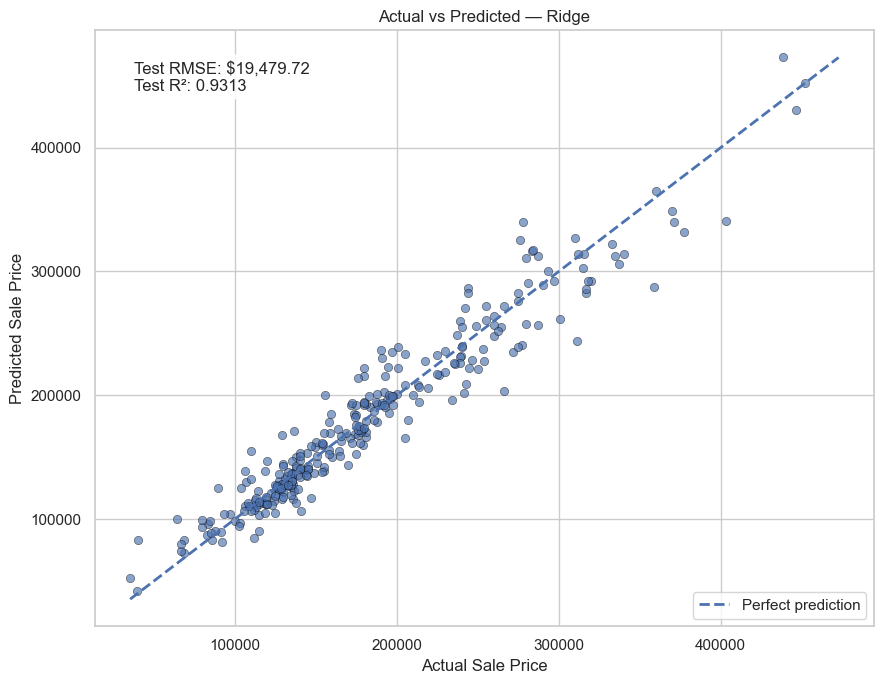

Best model selected by lowest 5-fold CV RMSE: Ridge
Test RMSE: $19,479.72
Test MAE:  $14,018.75
Test R²:   0.9313


In [42]:
# Choose the model using training-only cross-validation RMSE, then report its held-out test performance.
best_model_name = comparison_df.loc[
    comparison_df["5-Fold CV RMSE (price scale)"].idxmin(), "Model"
]
best_model = fitted_models[best_model_name]
best_predictions = predictions[best_model_name]

best_rmse = np.sqrt(mean_squared_error(y_test_actual, best_predictions))
best_r2 = r2_score(y_test_actual, best_predictions)

plt.figure(figsize=(9, 7))
plt.scatter(
    y_test_actual, best_predictions,
    alpha=0.65, edgecolor="black", linewidth=0.4
)

min_price = min(y_test_actual.min(), best_predictions.min())
max_price = max(y_test_actual.max(), best_predictions.max())
plt.plot(
    [min_price, max_price], [min_price, max_price],
    linestyle="--", linewidth=2, label="Perfect prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.text(
    0.05, 0.95,
    f"Test RMSE: ${best_rmse:,.2f}\nTest R²: {best_r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)
plt.legend()
plt.tight_layout()
plt.show()

print("Best model selected by lowest 5-fold CV RMSE:", best_model_name)
print(f"Test RMSE: ${best_rmse:,.2f}")
print(f"Test MAE:  ${mean_absolute_error(y_test_actual, best_predictions):,.2f}")
print(f"Test R²:   {best_r2:.4f}")

#### Identify and justify the best model

In this run, **Ridge is selected as the final model** because it has the lowest 5-fold CV RMSE (approximately $21,803), which is a better basis for model selection than repeatedly checking the test set. Its held-out test RMSE is approximately $19,480, MAE is $14,019 and R² is 0.9313. Lasso has a slightly lower test RMSE on this particular split, but Ridge's stronger average CV result suggests more stable performance across folds. Ridge also retains all features while shrinking coefficients, making it a reasonable balance of accuracy, stability and maintainability for a property-price estimation service.

### Step 7: Residual Analysis & Model Interpretation


#### 7.1  Residual Plots

In [43]:
# Residuals are calculated on the log-price scale, matching the target used for model training.
best_pred_log = best_model.predict(X_test_processed)
residuals = np.asarray(y_test) - best_pred_log
fitted_log_prices = best_pred_log

print("Best model:", best_model_name)
print(f"Mean residual (log scale): {residuals.mean():.4f}")
print(f"Residual standard deviation: {residuals.std():.4f}")
print(f"Residual skewness: {stats.skew(residuals):.4f}")

Best model: Ridge
Mean residual (log scale): -0.0061
Residual standard deviation: 0.1148
Residual skewness: -1.2430


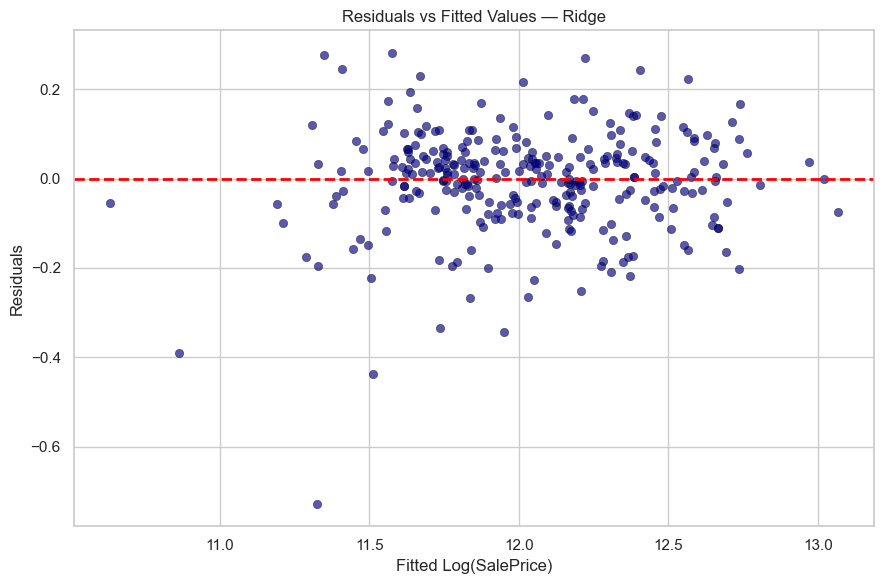

In [44]:
# Visualize residuals vs fitted values
plt.figure(figsize=(9, 6))

plt.scatter(
    best_pred_log,
    residuals,
    alpha=0.65,
    edgecolor="black",
    linewidth=0.4,
    color="darkblue"
)

plt.axhline(y=0, color="red", linestyle="--", linewidth=2)

plt.xlabel("Fitted Log(SalePrice)")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Fitted Values — {best_model_name}")
plt.tight_layout()
plt.show()

**Observation for this run:** Residuals are generally distributed around the zero line, without a strong curved pattern, although the spread is not perfectly uniform. A few large negative residuals are visible, meaning some expensive homes were overpredicted on the log-price scale. The overall pattern looks usable, but the outliers mean the model is not equally accurate for every property.

#### Histogram of residuals

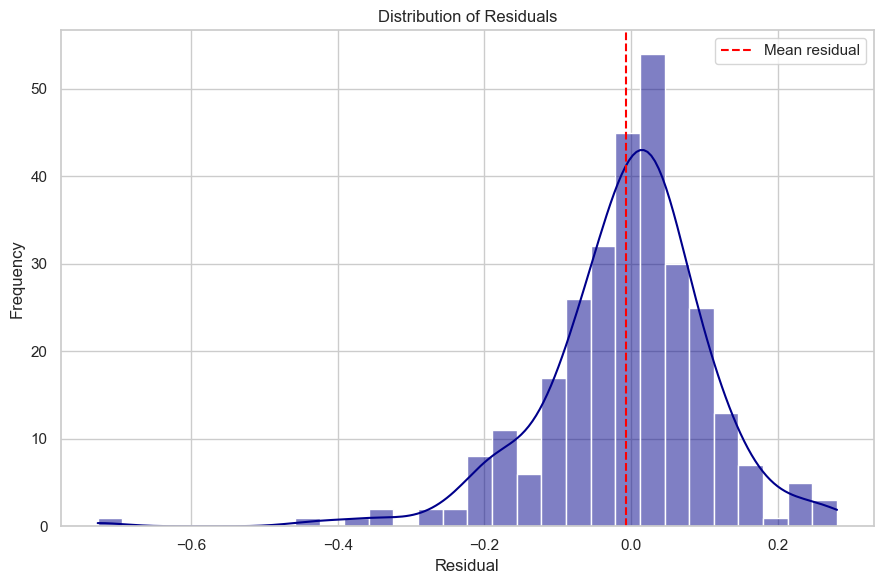

In [45]:
plt.figure(figsize=(9, 6))

sns.histplot(
    residuals,
    bins=30,
    kde=True,
    color="darkblue"
)

plt.axvline(
    residuals.mean(),
    color="red",
    linestyle="--",
    label="Mean residual"
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.legend()
plt.tight_layout()
plt.show()

**Observation for this run:** The residual histogram is concentrated near zero, but it has a longer negative tail than positive tail. This indicates the residuals are not perfectly symmetric or normally distributed. Most predictions are reasonably close, while a small number of homes have substantially larger errors.

#### Q-Q plot of residuals

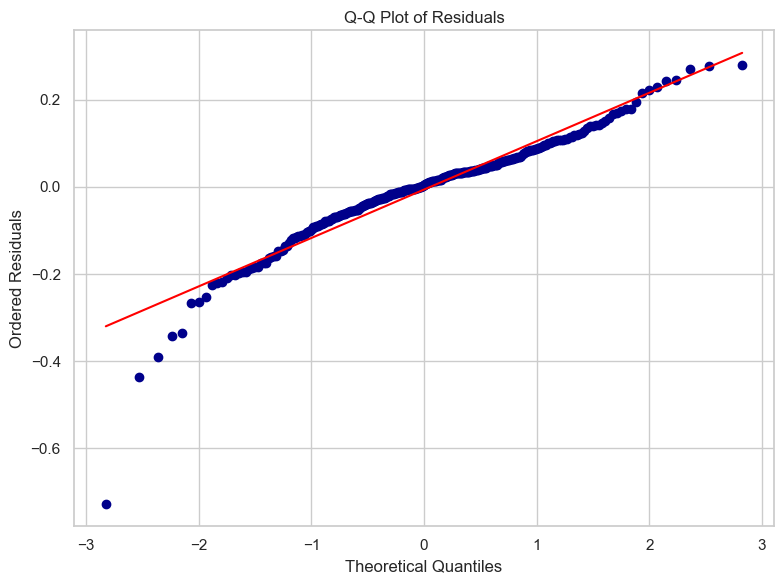

In [46]:
fig, ax = plt.subplots(figsize=(8, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=ax
)

ax.get_lines()[0].set_color("darkblue")
ax.get_lines()[1].set_color("red")

ax.set_title("Q-Q Plot of Residuals")
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Ordered Residuals")

plt.tight_layout()
plt.show()

**Observation for this run:** Most Q-Q points follow the reference line through the middle. The lower tail bends away from the line, including one notably extreme point, which indicates a heavy/long negative tail and departures from normality. This agrees with the residual histogram; predictions for unusual homes should therefore be treated cautiously.

#### 7.2 Business interpretation — Top 5 impactful features
This code automatically extracts the top five features according to your selected best model. For tree-based models, it uses feature importance; for Linear, Ridge, and Lasso, it uses the absolute coefficient magnitude.

In [47]:
# Extract the best model's importance scores or absolute coefficient magnitudes.
feature_names = preprocessor.get_feature_names_out()

if hasattr(best_model, "feature_importances_"):
    importance_values = best_model.feature_importances_
    importance_label = "Importance"
elif hasattr(best_model, "coef_"):
    importance_values = np.abs(np.asarray(best_model.coef_).ravel())
    importance_label = "Absolute coefficient"
else:
    raise ValueError("The selected model does not expose feature importance or coefficients.")

top_features = pd.DataFrame({
    "Feature": feature_names,
    importance_label: importance_values
}).sort_values(importance_label, ascending=False).head(5).reset_index(drop=True)

display(top_features)

,Feature,Absolute coefficient
0,categorical__MSZoning_C (all),0.086244
1,categorical__Neighborhood_StoneBr,0.081727
2,categorical__Neighborhood_Crawfor,0.073152
3,log_numeric__GrLivArea,0.070988
4,categorical__Functional_Typ,0.064486


#### Plot the top 5 features

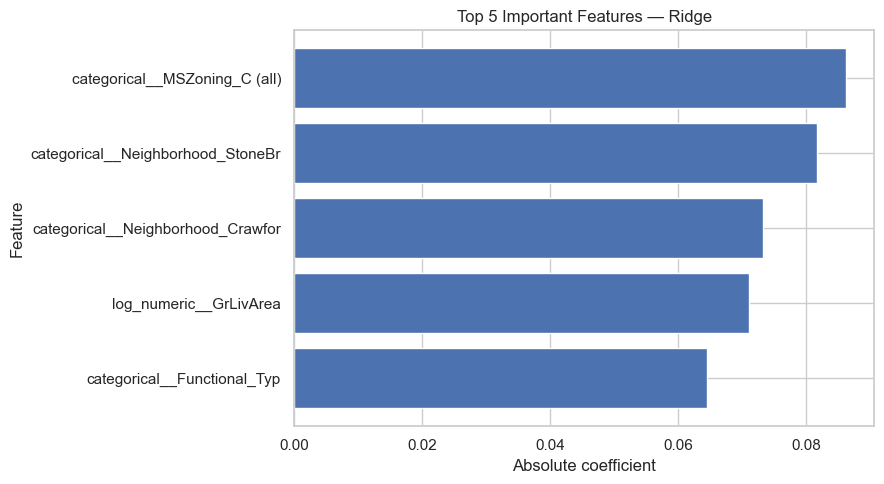

In [48]:
plt.figure(figsize=(9, 5))

plt.barh(
    top_features["Feature"][::-1],
    top_features[importance_label][::-1]
)

plt.xlabel(importance_label)
plt.ylabel("Feature")
plt.title(f"Top 5 Important Features — {best_model_name}")
plt.tight_layout()
plt.show()

#### Business interpretation of the actual top five features

The selected Ridge model ranks features by **absolute coefficient magnitude**. The current run produced the five entries shown in the table above:

- **`MSZoning_C (all)`** has the largest absolute coefficient and a negative coefficient in this fitted model. It represents a specific zoning category; interpret it cautiously because rare categories can receive unstable coefficients.
- **`Neighborhood_StoneBr`** has a positive coefficient, indicating that this neighborhood category is associated with a higher predicted price relative to the model's reference categories, after controlling for other included features.
- **`Neighborhood_Crawfor`** also has a positive coefficient, so this neighborhood indicator contributes positively relative to its reference categories in this fitted model.
- **`GrLivArea`** represents above-ground living area. More living space generally provides greater utility and is commonly associated with higher property prices.
- **`Functional_Typ`** represents a typical level of home functionality. Its coefficient captures how this category differs from the reference category used by one-hot encoding.

These are associations learned from this dataset, not proof that a feature causes a price change. For one-hot encoded columns, the interpretation is relative to the omitted reference category.

### Step 8: Pipeline, Deployment & GitHub Submission

#### Select the best model

The model is selected using the lowest 5-fold CV RMSE from Step 6. The held-out test set is reserved for the final performance report rather than model selection.

In [49]:
# Select using training-only 5-fold CV RMSE, keeping the test set for final evaluation.
best_model_name = comparison_df.loc[
    comparison_df["5-Fold CV RMSE (price scale)"].idxmin(), "Model"
]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: lowest 5-fold CV RMSE on training data.")
print("The held-out test set is used only to report final performance.")

Selected model: Ridge
Selection criterion: lowest 5-fold CV RMSE on training data.
The held-out test set is used only to report final performance.


#### Build and train the complete pipeline

In [50]:
import joblib
from sklearn.pipeline import Pipeline
from house_price_features import RawHousePriceModel

house_price_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(best_model))
])

house_price_pipeline.fit(X_train, y_train)
# Save a wrapper that also creates engineered features for raw Kaggle rows.
raw_input_model = RawHousePriceModel(house_price_pipeline)
joblib.dump(raw_input_model, "house_price_model.pkl")
print("Saved complete preprocessing + model pipeline to house_price_model.pkl")


Saved complete preprocessing + model pipeline to house_price_model.pkl


#### Load the saved pipeline and test 5 predictions

In [51]:
loaded_pipeline = joblib.load("house_price_model.pkl")

sample_houses = X_test.iloc[:5].copy()
predicted_log_prices = loaded_pipeline.predict(sample_houses)
predicted_prices = np.expm1(predicted_log_prices)
actual_prices = np.expm1(y_test.iloc[:5])

prediction_check = pd.DataFrame({
    "Actual Price": actual_prices.to_numpy(),
    "Predicted Price": predicted_prices
})
prediction_check["Absolute Error"] = (
    prediction_check["Predicted Price"] - prediction_check["Actual Price"]
).abs()

print("Loaded model:", best_model_name)
display(prediction_check.round(2))

Loaded model: Ridge


,Actual Price,Predicted Price,Absolute Error
0,190000.0,236236.15,46236.15
1,100000.0,98358.58,1641.42
2,115000.0,103284.26,11715.74
3,159000.0,169522.64,10522.64
4,315500.0,314397.49,1102.51


The output will show five actual house prices, five predicted prices, and the difference between them. The values come from the trained model.

Why use joblib? It saves the fitted preprocessing steps and model together. The saved wrapper also creates the engineered features and quality mappings, so raw Kaggle predictor rows can be passed directly. Keep `house_price_features.py` in the same folder as the PKL file.

#### Find the top three predictive features

The following cell reads importance scores from the fitted model inside the saved pipeline. For tree models it uses impurity-based feature importance; for linear models it uses absolute coefficient magnitude. These scores are model-specific and should not be interpreted as causal effects.

In [52]:
fitted_preprocessor = house_price_pipeline.named_steps["preprocessor"]
fitted_model = house_price_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_model, "feature_importances_"):
    importance_values = fitted_model.feature_importances_

elif hasattr(fitted_model, "coef_"):
    importance_values = np.abs(
        np.asarray(fitted_model.coef_).ravel()
    )

else:
    raise ValueError("Feature importance is unavailable for this model.")

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 3 Predictive Features:")
print(feature_importance_df.head(3).to_string(index=False))

Top 3 Predictive Features:
                          Feature  Importance
    categorical__MSZoning_C (all)    0.086244
categorical__Neighborhood_StoneBr    0.081727
categorical__Neighborhood_Crawfor    0.073152


These are the top features according to the chosen model's importance measure. In the Ridge model, absolute coefficient magnitude is used, so the sign is not shown in this ranking; a separate coefficient table is needed to see direction. For one-hot encoded categories, a feature represents one category compared with the reference category. Importance indicates predictive association, not causation.